<a href="https://colab.research.google.com/github/nutangaonkar/CSL701-CE09-Machine-Learning-Lab/blob/main/Experiments/ML_Experiment_9.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

###  ML Experiment Number 9
Student Name : Nutan Nandkishor Gaonkar

Batch : CE01


Roll Number : CE09



### **Aim**

To implement Classification and Regression Trees (CART) using Python on the Palmer Penguins Dataset Extended.

## Objectives

1. To understand the concept and working of the CART algorithm.
2. To implement Decision Tree Classification using Python.   
3. To visualize the constructed Decision Tree structure and decision boundaries.   
4. To analyze impurity measures such as Gini Index and Entropy.
5. To compare the decision boundary of a Decision Tree with a linear classification boundary (e.g., Logistic Regression).   
6. To evaluate and compare the performance of both classifiers.

# Relevant Theory

###Classification and Regression Trees (CART)
CART is a non-parametric supervised machine learning algorithm used for both classification and regression tasks. It builds a binary decision tree by recursively splitting the dataset based on feature values that maximize information gain or minimize impurity.

A tree consists of:

* Root Node: The topmost node representing the entire dataset.

* Internal Nodes: Decision points based on feature splits.

* Leaf/Terminal Nodes: Output class labels or predictions.

Impurity MeasuresGini Index (Gini Impurity): Measures the frequency with which a randomly chosen element from the set would be incorrectly labeled.$$Gini(D) = 1 - \sum_{i=1}^{k} p_i^2$$where $p_i$ is the probability of an item belonging to class $i$.Entropy & Information Gain: Measures the amount of impurity or randomness in the data.$$Entropy(D) = -\sum_{i=1}^{k} p_i \log_2(p_i)$$Dataset InformationGet the Palmer Penguins Dataset Extended from Kaggle using the following link:https://www.kaggle.com/datasets/samybaladram/palmers-penguin-dataset-extended The Palmer Penguins dataset contains measurements of penguin species across islands in the Palmer Archipelago:AdelieChinstrapGentooThe primary numerical features are:culmen_length_mm (or bill_length_mm)culmen_depth_mm (or bill_depth_mm)flipper_length_mmbody_mass_gFor visualization, we will use: culmen_length_mm and flipper_length_mm.

# Task 1: Import Libraries and Load Dataset
* Load essential libraries (numpy, pandas, matplotlib, seaborn, sklearn).

* Load the Palmer Penguins Extended dataset.
---

In [2]:
# Task 1: Import Libraries and Load Dataset

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Upload the dataset
from google.colab import files
uploaded = files.upload()

# Load the CSV file
filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

# Display dataset information
print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nFirst 5 rows:")
display(df.head())

print("\nColumn names:")
print(df.columns.tolist())



Saving palmerpenguins_extended.csv to palmerpenguins_extended.csv
Dataset loaded successfully!
Dataset shape: (3430, 11)

First 5 rows:


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,diet,life_stage,health_metrics,year
0,Adelie,Biscoe,53.4,17.8,219.0,5687.0,female,fish,adult,overweight,2021
1,Adelie,Biscoe,49.3,18.1,245.0,6811.0,female,fish,adult,overweight,2021
2,Adelie,Biscoe,55.7,16.6,226.0,5388.0,female,fish,adult,overweight,2021
3,Adelie,Biscoe,38.0,15.6,221.0,6262.0,female,fish,adult,overweight,2021
4,Adelie,Biscoe,60.7,17.9,177.0,4811.0,female,fish,juvenile,overweight,2021



Column names:
['species', 'island', 'bill_length_mm', 'bill_depth_mm', 'flipper_length_mm', 'body_mass_g', 'sex', 'diet', 'life_stage', 'health_metrics', 'year']


# Task 2: Select Features and Target & Preprocess

* Handle missing values (e.g., drop rows with missing values or impute with median).   
* Select features ($X$) such as culmen_length_mm, culmen_depth_mm, flipper_length_mm, body_mass_g and set species as the target label ($y$).   
* Encode categorical targets if necessary using LabelEncoder.

In [3]:

# Task 2: Select Features and Target & Preprocess

# 1. Check whether the dataset contains valid data
print("Original dataset shape:", df.shape)

if df.empty or df.isna().all(axis=1).all():
    raise ValueError(
        "The dataset contains no valid rows. "
        "Please reload the correct CSV file in Task 1."
    )

# 2. Remove completely empty rows
df = df.dropna(how="all").copy()

# 3. Select the required columns
features = [
    "bill_length_mm",
    "bill_depth_mm",
    "flipper_length_mm",
    "body_mass_g"
]
target = "species"

# 4. Check that all required columns exist
required_columns = features + [target]
missing_columns = [col for col in required_columns if col not in df.columns]

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

# 5. Convert feature columns to numeric values
for col in features:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# 6. Handle missing values in required columns
df = df.dropna(subset=required_columns).copy()

# 7. Select input features (X) and target (y)
X = df[features]
y = df[target].astype(str)

# 8. Encode species labels into numbers
label_encoder = LabelEncoder()
y = label_encoder.fit_transform(y)

# 9. Display results
print("\nDataset shape after preprocessing:", df.shape)
print("Features (X) shape:", X.shape)
print("Target (y) shape:", y.shape)

print("\nFeature columns:")
print(X.head())

print("\nSpecies classes:", label_encoder.classes_)
print("Encoded target values:", np.unique(y))


Original dataset shape: (3430, 11)

Dataset shape after preprocessing: (3430, 11)
Features (X) shape: (3430, 4)
Target (y) shape: (3430,)

Feature columns:
   bill_length_mm  bill_depth_mm  flipper_length_mm  body_mass_g
0            53.4           17.8              219.0       5687.0
1            49.3           18.1              245.0       6811.0
2            55.7           16.6              226.0       5388.0
3            38.0           15.6              221.0       6262.0
4            60.7           17.9              177.0       4811.0

Species classes: ['Adelie' 'Chinstrap' 'Gentoo']
Encoded target values: [0 1 2]


# Task 3: Split the Data

* Divide the dataset into training and testing sets using train_test_split.

In [4]:

# Task 3: Split the Data

from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# Display the shapes of the datasets
print("Training data shape (X_train):", X_train.shape)
print("Testing data shape (X_test):", X_test.shape)
print("Training labels shape (y_train):", y_train.shape)
print("Testing labels shape (y_test):", y_test.shape)


Training data shape (X_train): (2744, 4)
Testing data shape (X_test): (686, 4)
Training labels shape (y_train): (2744,)
Testing labels shape (y_test): (686,)


# Task 4: Implement CART Classifier

* Create a DecisionTreeClassifier model using the Gini criterion (or Entropy).   
* Fit the model on the training data and make predictions on the test set.   

In [5]:

# Task 4: Implement CART Classifier

from sklearn.tree import DecisionTreeClassifier

# Create the Decision Tree model using Gini criterion
cart_model = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)

# Train the model using training data
cart_model.fit(X_train, y_train)

# Predict the species for testing data
y_pred = cart_model.predict(X_test)

print("CART model trained successfully!")

print("\nFirst 10 actual labels:")
print(y_test[:10])

print("\nFirst 10 predicted labels:")
print(y_pred[:10])


CART model trained successfully!

First 10 actual labels:
[0 2 0 0 0 2 1 0 2 0]

First 10 predicted labels:
[2 2 0 0 2 2 1 0 0 0]


# Task 5: Evaluate CART Model

* Accuracy: Calculate classification accuracy.   
* Confusion Matrix: Generate the matrix to analyze misclassifications across species.
* Classification Report: Output Precision, Recall, F1-Score, and Support.   

CART Classification Accuracy: 0.4518950437317784
Accuracy Percentage: 45.18950437317784 %

Confusion Matrix:
[[155  64  93]
 [ 48  33  44]
 [ 76  51 122]]

Classification Report:
              precision    recall  f1-score   support

      Adelie       0.56      0.50      0.52       312
   Chinstrap       0.22      0.26      0.24       125
      Gentoo       0.47      0.49      0.48       249

    accuracy                           0.45       686
   macro avg       0.42      0.42      0.42       686
weighted avg       0.46      0.45      0.46       686



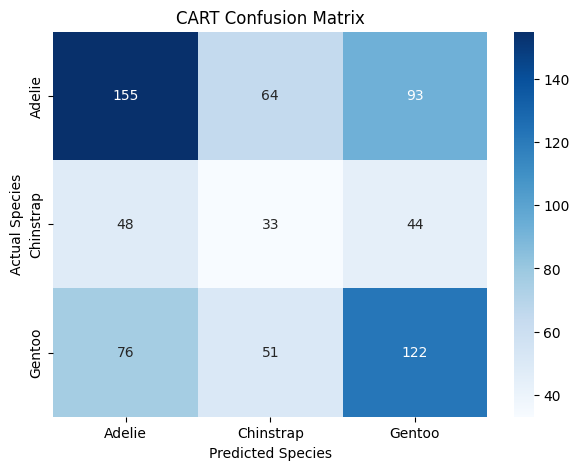

In [6]:

# Task 5: Evaluate CART Model

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)

# 1. Calculate accuracy
accuracy = accuracy_score(y_test, y_pred)
print("CART Classification Accuracy:", accuracy)
print("Accuracy Percentage:", accuracy * 100, "%")

# 2. Generate confusion matrix
cm = confusion_matrix(y_test, y_pred)

print("\nConfusion Matrix:")
print(cm)

# 3. Generate classification report
print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        labels=[0, 1, 2],
        target_names=label_encoder.classes_,
        zero_division=0
    )
)

# 4. Visualize confusion matrix
plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.xlabel("Predicted Species")
plt.ylabel("Actual Species")
plt.title("CART Confusion Matrix")
plt.show()


# Task 6: Visualize Decision Tree & Decision Boundary

* Visualize Tree Structure: Plot the decision tree diagram using sklearn.tree.plot_tree.
* Select 2-D Features: Select culmen_length_mm and flipper_length_mm.   
* Train 2-D Model & Plot Boundary: Train the decision tree on 2D data and plot axis-aligned rectangular decision boundaries along with data points


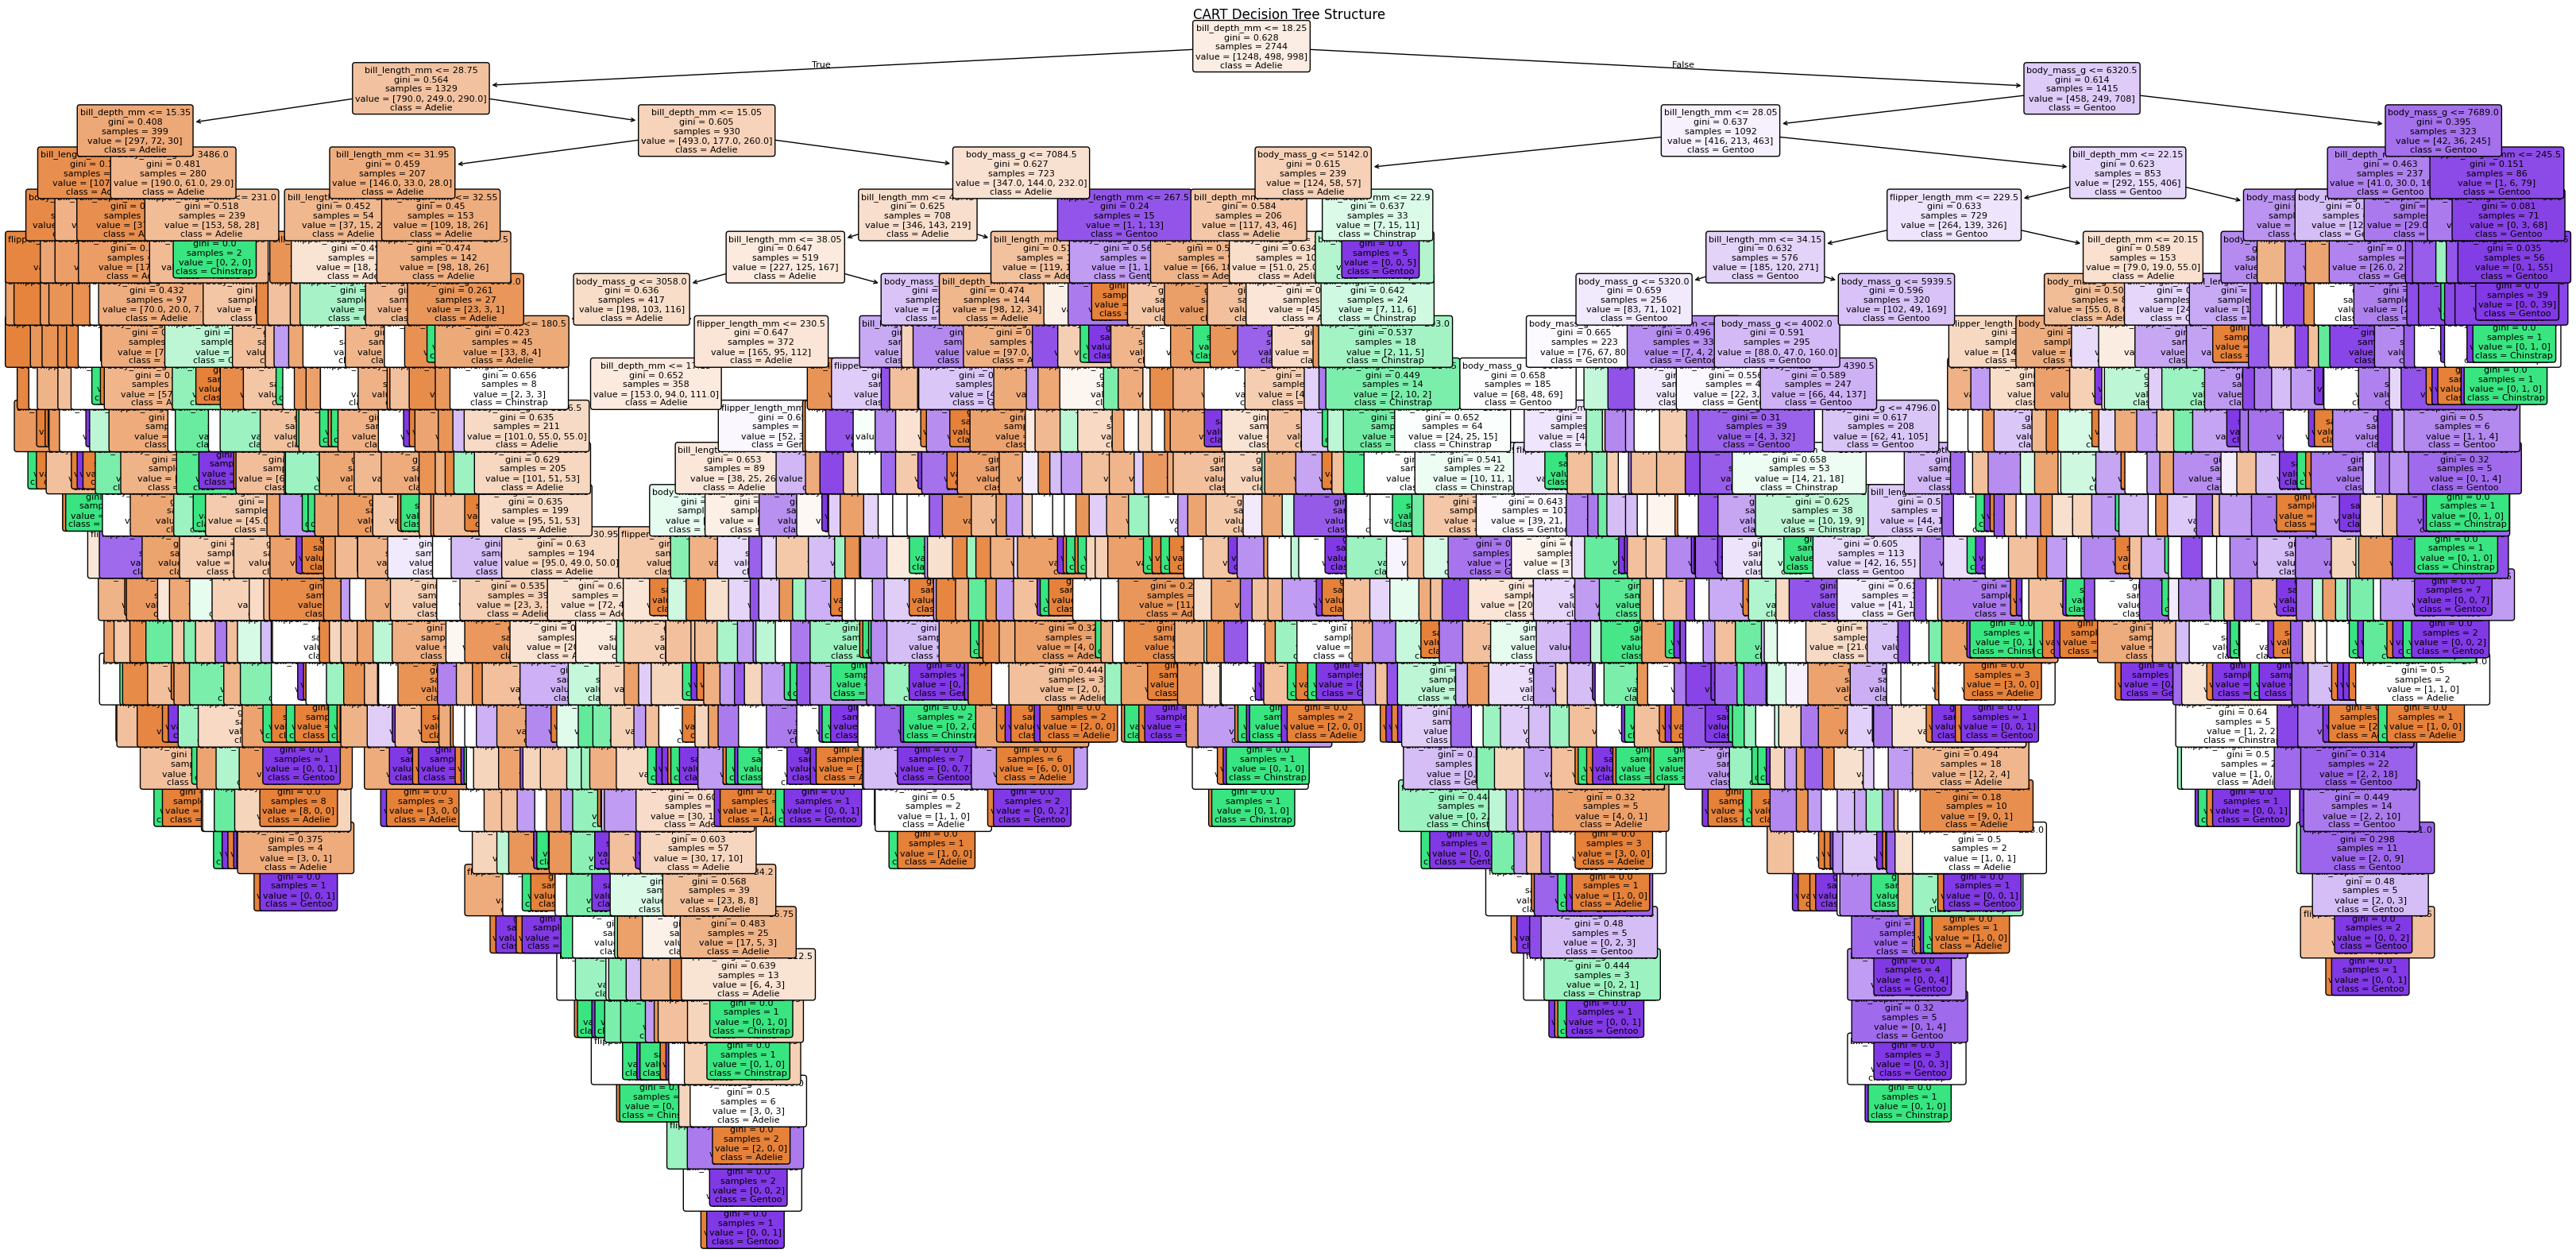

In [8]:

# Task 6A: Visualize the Decision Tree Structure

from sklearn.tree import plot_tree

plt.figure(figsize=(40, 20))

plot_tree(
    cart_model,
    feature_names=features,
    class_names=label_encoder.classes_,
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("CART Decision Tree Structure")
plt.show()


# Task 7: Normal Linear Classification Boundary

* Train a Logistic Regression model using the same two features as a normal linear baseline.   
* Visualize its linear decision boundary.

Logistic Regression Accuracy: 52.62 %


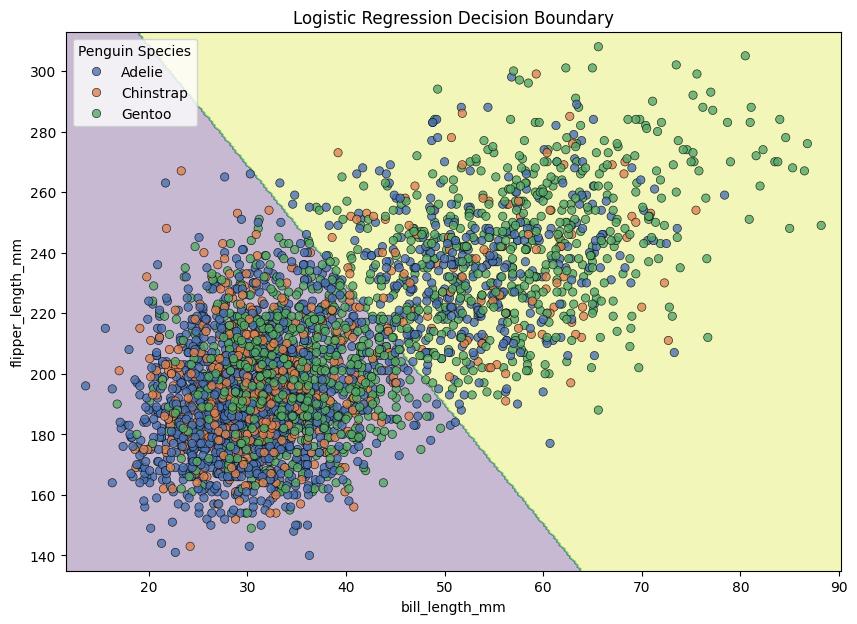

In [12]:

# Task 7: Logistic Regression Decision Boundary

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

# 1. Select the two features
bill_feature = (
    "culmen_length_mm"
    if "culmen_length_mm" in df.columns
    else "bill_length_mm"
)
flipper_feature = "flipper_length_mm"

# 2. Prepare the data
X_2d = df[[bill_feature, flipper_feature]].copy()
y_species = df["species"].astype(str)

# Remove missing values
data = pd.concat([X_2d, y_species.rename("species")], axis=1)
data = data.dropna()

X_2d = data[[bill_feature, flipper_feature]]
y_species = data["species"]

# Encode species labels
label_encoder = LabelEncoder()
y_2d = label_encoder.fit_transform(y_species)

# 3. Split data into training and testing sets
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

# 4. Train Logistic Regression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X2_train, y2_train)

# 5. Predict and calculate accuracy
y2_pred_logistic = logistic_model.predict(X2_test)

print("Logistic Regression Accuracy:",
      round(accuracy_score(y2_test, y2_pred_logistic) * 100, 2), "%")

# 6. Create the decision-boundary grid
x_min = X_2d[bill_feature].min() - 2
x_max = X_2d[bill_feature].max() + 2
y_min = X_2d[flipper_feature].min() - 5
y_max = X_2d[flipper_feature].max() + 5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame({
    bill_feature: xx.ravel(),
    flipper_feature: yy.ravel()
})

Z = logistic_model.predict(grid).reshape(xx.shape)

# 7. Plot the decision boundary
plt.figure(figsize=(10, 7))

plt.contourf(xx, yy, Z, alpha=0.3, cmap="viridis")

sns.scatterplot(
    data=data,
    x=bill_feature,
    y=flipper_feature,
    hue="species",
    palette="deep",
    edgecolor="black",
    alpha=0.8
)

plt.xlabel(bill_feature)
plt.ylabel(flipper_feature)
plt.title("Logistic Regression Decision Boundary")
plt.legend(title="Penguin Species")
plt.show()


# Task 8: Compare CART and Normal Linear Boundary

* Plot both the Decision Tree (axis-aligned non-linear) and Logistic Regression (linear) decision boundaries on side-by-side subplots.   * Compare how non-linear CART boundaries differ from straight linear hyperplanes.

CART Accuracy: 43.88 %
Logistic Regression Accuracy: 52.62 %


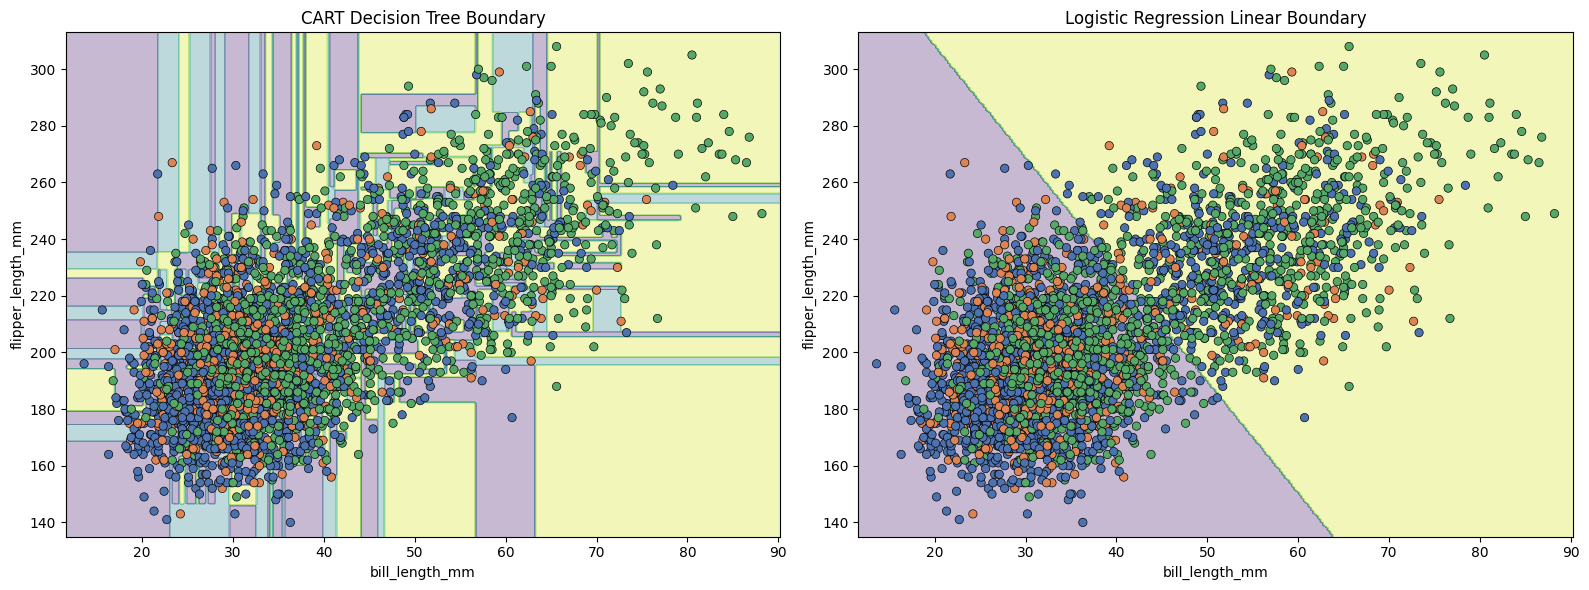

In [14]:

# Task 8: Compare CART and Logistic Regression Boundaries

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import accuracy_score

# 1. Select the two features
bill_feature = (
    "culmen_length_mm"
    if "culmen_length_mm" in df.columns
    else "bill_length_mm"
)
flipper_feature = "flipper_length_mm"

# 2. Prepare and clean data
data = df[[bill_feature, flipper_feature, "species"]].copy()

data[bill_feature] = pd.to_numeric(data[bill_feature], errors="coerce")
data[flipper_feature] = pd.to_numeric(
    data[flipper_feature], errors="coerce"
)
data = data.dropna()

X_2d = data[[bill_feature, flipper_feature]]
label_encoder = LabelEncoder()
y_2d = label_encoder.fit_transform(data["species"].astype(str))

# 3. Split the data
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X_2d,
    y_2d,
    test_size=0.2,
    random_state=42,
    stratify=y_2d
)

# 4. Train CART Decision Tree
cart_2d = DecisionTreeClassifier(
    criterion="gini",
    random_state=42
)
cart_2d.fit(X2_train, y2_train)

# 5. Train Logistic Regression
logistic_model = LogisticRegression(max_iter=1000)
logistic_model.fit(X2_train, y2_train)

# 6. Print accuracy
print("CART Accuracy:",
      round(accuracy_score(y2_test, cart_2d.predict(X2_test)) * 100, 2), "%")

print("Logistic Regression Accuracy:",
      round(accuracy_score(y2_test, logistic_model.predict(X2_test)) * 100, 2), "%")

# 7. Create grid for decision boundaries
x_min = X_2d[bill_feature].min() - 2
x_max = X_2d[bill_feature].max() + 2
y_min = X_2d[flipper_feature].min() - 5
y_max = X_2d[flipper_feature].max() + 5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = pd.DataFrame({
    bill_feature: xx.ravel(),
    flipper_feature: yy.ravel()
})

Z_cart = cart_2d.predict(grid).reshape(xx.shape)
Z_logistic = logistic_model.predict(grid).reshape(xx.shape)

# 8. Plot both boundaries side by side
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# CART plot
axes[0].contourf(xx, yy, Z_cart, alpha=0.3, cmap="viridis")
sns.scatterplot(
    data=data, x=bill_feature, y=flipper_feature,
    hue="species", palette="deep",
    edgecolor="black", ax=axes[0], legend=False
)
axes[0].set_title("CART Decision Tree Boundary")
axes[0].set_xlabel(bill_feature)
axes[0].set_ylabel(flipper_feature)

# Logistic Regression plot
axes[1].contourf(xx, yy, Z_logistic, alpha=0.3, cmap="viridis")
sns.scatterplot(
    data=data, x=bill_feature, y=flipper_feature,
    hue="species", palette="deep",
    edgecolor="black", ax=axes[1], legend=False
)
axes[1].set_title("Logistic Regression Linear Boundary")
axes[1].set_xlabel(bill_feature)
axes[1].set_ylabel(flipper_feature)

plt.tight_layout()
plt.show()


# Task 9: Compare Performance

* Compare the evaluation metrics (Accuracy, Confusion Matrix, Classification Report) of the CART Classifier vs. Logistic Regression.

========== ACCURACY COMPARISON ==========
CART Accuracy: 0.4388 (43.88%)
Logistic Regression Accuracy: 0.5262 (52.62%)

========== CART CONFUSION MATRIX ==========
[[156  52 104]
 [ 55  31  39]
 [ 83  52 114]]

===== LOGISTIC REGRESSION CONFUSION MATRIX =====
[[245   0  67]
 [102   0  23]
 [133   0 116]]

========== CART CLASSIFICATION REPORT ==========
              precision    recall  f1-score   support

      Adelie       0.53      0.50      0.51       312
   Chinstrap       0.23      0.25      0.24       125
      Gentoo       0.44      0.46      0.45       249

    accuracy                           0.44       686
   macro avg       0.40      0.40      0.40       686
weighted avg       0.44      0.44      0.44       686

===== LOGISTIC REGRESSION CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

      Adelie       0.51      0.79      0.62       312
   Chinstrap       0.00      0.00      0.00       125
      Gentoo       0.56      0.47      0.51   

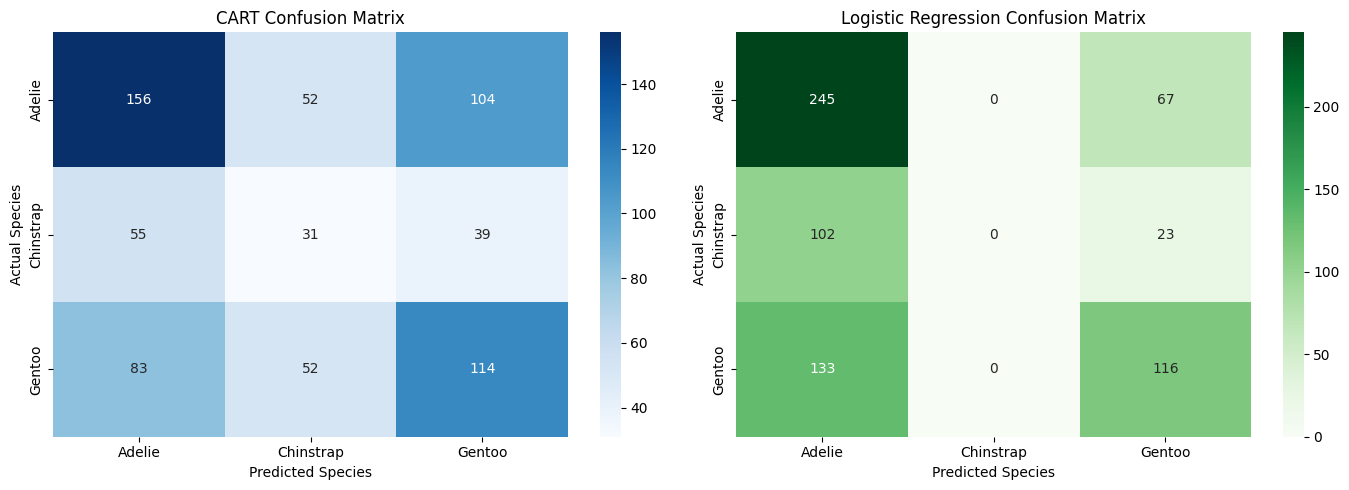

In [15]:

# Task 9: Compare CART and Logistic Regression Performance

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report
)
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Predict using both models
y_pred_cart = cart_2d.predict(X2_test)
y_pred_logistic = logistic_model.predict(X2_test)

# 2. Calculate accuracy
cart_accuracy = accuracy_score(y2_test, y_pred_cart)
logistic_accuracy = accuracy_score(y2_test, y_pred_logistic)

print("========== ACCURACY COMPARISON ==========")
print(f"CART Accuracy: {cart_accuracy:.4f} ({cart_accuracy * 100:.2f}%)")
print(f"Logistic Regression Accuracy: {logistic_accuracy:.4f} ({logistic_accuracy * 100:.2f}%)")

# 3. Confusion matrices
cm_cart = confusion_matrix(y2_test, y_pred_cart)
cm_logistic = confusion_matrix(y2_test, y_pred_logistic)

print("\n========== CART CONFUSION MATRIX ==========")
print(cm_cart)

print("\n===== LOGISTIC REGRESSION CONFUSION MATRIX =====")
print(cm_logistic)

# 4. Classification reports
print("\n========== CART CLASSIFICATION REPORT ==========")
print(classification_report(
    y2_test,
    y_pred_cart,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

print("===== LOGISTIC REGRESSION CLASSIFICATION REPORT =====")
print(classification_report(
    y2_test,
    y_pred_logistic,
    labels=range(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))

# 5. Plot confusion matrices side by side
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(
    cm_cart, annot=True, fmt="d", cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    ax=axes[0]
)
axes[0].set_title("CART Confusion Matrix")
axes[0].set_xlabel("Predicted Species")
axes[0].set_ylabel("Actual Species")

sns.heatmap(
    cm_logistic, annot=True, fmt="d", cmap="Greens",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_,
    ax=axes[1]
)
axes[1].set_title("Logistic Regression Confusion Matrix")
axes[1].set_xlabel("Predicted Species")
axes[1].set_ylabel("Actual Species")

plt.tight_layout()
plt.show()


# Conclusion

The experiment successfully demonstrated the implementation of the Classification and Regression Tree (CART) algorithm using the Palmer Penguins Extended dataset. The dataset was preprocessed to handle missing values before training. The decision tree structure was visualized, showcasing the hierarchical splits based on feature thresholds. A comparison with a normal linear boundary (Logistic Regression) highlighted CART's ability to create non-linear, axis-aligned decision boundaries to separate different penguin species.